<a href="https://colab.research.google.com/github/digshu9242/DAVlab-i1/blob/main/hirerarchial_xlustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (1036, 25)

First 5 records:
   id  awardYear           category  prizeAmount  prizeAmountAdjusted  \
0   1       2003          Chemistry      1997865              8403252   
1   2       1952          Chemistry      7736725              3091006   
2   3       1993          Chemistry      9458092              7151785   
3   4       1915  Economic Sciences      5047954              3688725   
4   5       2007  Economic Sciences      4167136              3206487   

         name gender  ageAtAward  extra_col_9  extra_col_10  ...  \
0  Laureate_1    org          39            6            96  ...   
1  Laureate_2   male          35           62             0  ...   
2  Laureate_3   male          78           41            50  ...   
3  Laureate_4   male          73           41             4  ...   
4  Laureate_5   male          86           58            12  ...   

   extra_col_16  extra_col_17  extra_col_18  extra_col_19  extra_col_20  \
0            58            11    

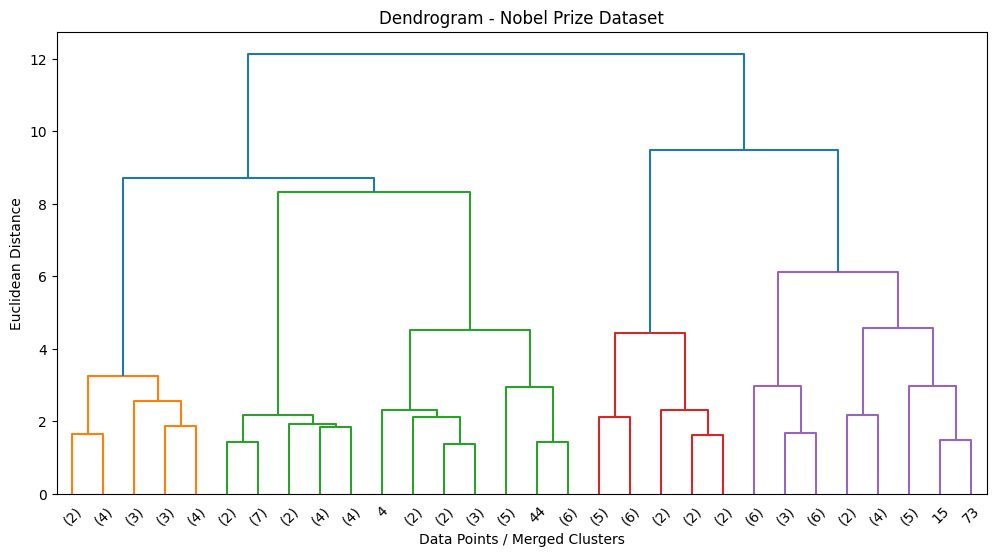

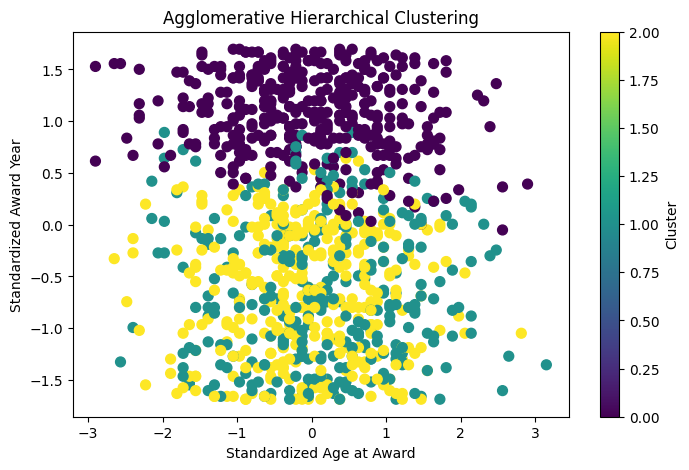


Cluster assignments:
[0 1 0 ... 0 0 0]

First 10 data points and their clusters:
Data Point: 0 Cluster: 0
Data Point: 1 Cluster: 1
Data Point: 2 Cluster: 0
Data Point: 3 Cluster: 1
Data Point: 4 Cluster: 0
Data Point: 5 Cluster: 2
Data Point: 6 Cluster: 2
Data Point: 7 Cluster: 1
Data Point: 8 Cluster: 0
Data Point: 9 Cluster: 0

Cluster Statistics:
                      ageAtAward    awardYear  prizeAmountAdjusted
Hierarchical_Cluster                                              
0                      59.112821  2000.323077         7.807320e+06
1                      61.328814  1938.644068         4.859939e+06
2                      58.464387  1938.527066         9.415650e+06

Hierarchical clustering completed successfully!
Output saved as nobel_prize_hierarchical_clustered.csv


In [3]:
# HIERARCHICAL CLUSTERING ON NOBEL PRIZE DATASET

# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Step 2: Load the dataset
nobel_df = pd.read_csv("nobel_prize_clustered.csv")
print("Dataset shape:", nobel_df.shape)
print("\nFirst 5 records:")
print(nobel_df.head())

# Step 3: Select numerical features
features_df = nobel_df[
    ["ageAtAward", "awardYear", "prizeAmountAdjusted"]
].copy()

# Convert columns to numeric
features_df = features_df.apply(pd.to_numeric, errors="coerce")

# Handle missing values
features_df = features_df.dropna()
print("\nSelected data shape:", features_df.shape)

# Step 4: Standardize the data
std_scaler = StandardScaler()
scaled_features = std_scaler.fit_transform(features_df)

# Step 5: Create a dendrogram
# Use a sample for better visualization
subset_limit = min(100, len(scaled_features))
linkage_matrix = linkage(
    scaled_features[:subset_limit],
    method='ward'
)
plt.figure(figsize=(12, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30
)
plt.title("Dendrogram - Nobel Prize Dataset")
plt.xlabel("Data Points / Merged Clusters")
plt.ylabel("Euclidean Distance")
plt.show()

# Step 6: Apply Agglomerative Clustering
agg_clustering = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)
cluster_labels = agg_clustering.fit_predict(scaled_features)

# Step 7: Add cluster assignments
output_df = nobel_df.loc[features_df.index].copy()
output_df["Hierarchical_Cluster"] = cluster_labels

# Step 8: Visualize the clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    scaled_features[:, 0],
    scaled_features[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=50
)
plt.xlabel("Standardized Age at Award")
plt.ylabel("Standardized Award Year")
plt.title("Agglomerative Hierarchical Clustering")
plt.colorbar(label="Cluster")
plt.show()

# Step 9: Display cluster assignments
print("\nCluster assignments:")
print(cluster_labels)
print("\nFirst 10 data points and their clusters:")
for idx in range(min(10, len(cluster_labels))):
    print(
        "Data Point:", idx,
        "Cluster:", cluster_labels[idx]
    )

# Step 10: Display cluster statistics
print("\nCluster Statistics:")
print(
    output_df.groupby("Hierarchical_Cluster")[
        ["ageAtAward", "awardYear", "prizeAmountAdjusted"]
    ].mean()
)

# Step 11: Save the clustered dataset
output_df.to_csv(
    "nobel_prize_hierarchical_clustered.csv",
    index=False
)
print("\nHierarchical clustering completed successfully!")
print("Output saved as nobel_prize_hierarchical_clustered.csv")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')